In [1]:
# Notebook 3 — Transformer tự build (train from scratch) cho bài toán
# khôi phục dấu tiếng Việt, + so sánh 4 hệ + phân tích lỗi + demo Gradio.
# Notebook này độc lập với Notebook 1 nhưng tải lại đúng corpus 100k câu
# (cùng code, cùng seed 42) nên train/val/test giống hệt Notebook 1.
# Công thức bài toán: phân loại token ở mức TỪ — mỗi từ không dấu được
# xếp vào 1 MẪU DẤU (pattern): các ký tự có dấu tại những vị trí có thể
# mang dấu của từ đó. Vd "được" -> mẫu "đượ", "có" -> "ó", "hoàn" -> "oà".
# Cùng một mẫu có nghĩa giống nhau cho mọi từ nên model học được quy
# luật dấu từ ngữ cảnh (xem Cell 2). Model: Transformer encoder nhỏ
# (4 lớp, hidden 256, 8 heads, ~9,5M tham số), train 20 epoch.
# Cập nhật 17/11 (review code): thêm torch.manual_seed (Cell 3), assert
# kiểm tra khớp dữ liệu (Cell 1), masking mẫu tương thích khi dự đoán
# (Cell 5/9). Số trong báo cáo (92,5%) đo ngày 16/11, trước các sửa đổi
# này — chạy lại có thể lệch nhẹ (seed làm train tái tạo được; masking
# chỉ có thể làm số tăng lên, không giảm).
# Tinh chỉnh 18/11: PhoBERT 6 epoch (Notebook 2), tự build 20 epoch +
# giải mã Viterbi + bigram (Cell 3/5) — chạy lại để lấy số mới, kỳ vọng
# PhoBERT lên cao 80s, tự build tăng nhẹ; số 16/11 giữ làm baseline.

# Cell 1 — Hàm bỏ dấu + tải Wikipedia + chia train/val/test
import unicodedata, re, random, collections

def strip_diacritics(s: str) -> str:
    # Bỏ dấu tiếng Việt: tách dấu bằng NFD rồi loại bỏ ký tự dấu,
    # riêng đ/Đ xử lý tay vì NFD không tách được.
    s = s.replace("đ", "d").replace("Đ", "D")
    return "".join(c for c in unicodedata.normalize("NFD", s)
                   if unicodedata.category(c) != "Mn")

from datasets import load_dataset

N_ARTICLES = 10000
TARGET_SENTENCES = 100000

ds = load_dataset("wikimedia/wikipedia", "20231101.vi",
                  split="train", streaming=True)
sentences, seen = [], set()
n_read = 0
for ex in ds:
    n_read += 1
    if n_read > N_ARTICLES:
        break
    text = ex["text"].replace("\n", " ")
    for s in re.split(r"(?<=[.!?…])\s+(?=[A-ZÀ-ỸĐ])", text):
        s = re.sub(r"\s+", " ", s).strip()
        w = s.split()
        if not (5 <= len(w) <= 40):
            continue
        if "http" in s or s.count("=") > 2:
            continue
        if sum(c.isdigit() for c in s) / max(len(s), 1) > 0.15:
            continue
        if s in seen:
            continue
        seen.add(s)
        sentences.append(s)
        if len(sentences) >= TARGET_SENTENCES:
            break
    if len(sentences) >= TARGET_SENTENCES:
        break
print(f"bai viet da doc: {n_read} | cau giu lai: {len(sentences)}")

random.seed(42)
# Chuẩn hóa câu về NFC: Wikipedia có chỗ lưu dấu dạng tách rời (NFD,
# vd "ê" = "e" + dấu mũ tách riêng) khiến từ có dấu và từ không dấu
# lệch độ dài. NFC gộp mỗi ký tự có dấu thành 1 ký tự duy nhất.
pairs = [(strip_diacritics(s), unicodedata.normalize("NFC", s))
         for s in sentences]
random.shuffle(pairs)
n = len(pairs)
n_train, n_val = int(n * 0.8), int(n * 0.1)
train = pairs[:n_train]
val = pairs[n_train:n_train + n_val]
test = pairs[n_train + n_val:]
print(f"train {len(train)} | val {len(val)} | test {len(test)}")

# Kiểm tra khớp với Notebook 1: tổng số từ phải = 2.387.449 —
# nếu khác thì tập dữ liệu đã lệch.
words = [w for _, acc in pairs for w in acc.split()]
print(f"tong so tu: {len(words)}")
# Dừng ngay nếu tập dữ liệu lệch khỏi Notebook 1.
assert len(words) == 2387449, f"tap du lieu lech: {len(words)} tu (muon 2.387.449)"

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

bai viet da doc: 1501 | cau giu lai: 100000
train 80000 | val 10000 | test 10000
tong so tu: 2387449


In [2]:
# Cell 2 — Mã hóa dấu thành "mẫu dấu" (signature)
# Thay vì bắt model chọn 1 trong các dạng có dấu của từng từ (nhãn khác
# nhau cho mỗi từ, model khó học), ta tách riêng PHẦN DẤU ra khỏi từ.
# Mẫu dấu của một từ = tuple các đơn vị có dấu tại những vị trí có thể
# mang dấu, theo đúng thứ tự. Ví dụ: "được" -> ("đ", "ư", "ợ");
# "có" -> ("ó",); "hoàn" -> ("o", "à") (o giữ nguyên, a->à).
# Từ không có vị trí mang dấu (vd "123", "Mr") có mẫu rỗng ().
# MODIFIABLE để CỐ ĐỊNH theo tiếng Việt (nguyên âm a e i o u y + đ),
# không học từ dữ liệu: Wikipedia chứa chữ nước ngoài (Thái, Khmer,
# Hy Lạp...) nên học từ dữ liệu làm số mẫu dấu bùng nổ tới hàng chục
# nghìn và model học kém. Tên riêng nước ngoài chứa dấu phụ âm ngoài
# tiếng Việt (vd "Rêš", "François") thì không mã hóa được bằng mẫu
# dấu tiếng Việt — chúng chiếm rất ít (0,03%) và được bỏ qua khi train.
# Mẫu dấu lưu dạng tuple vì Wikipedia có chỗ lưu dấu dạng tách rời
# (vd "ê" = "e" + dấu mũ riêng): tách từ thành đơn vị (ký tự gốc +
# dấu đi kèm) bằng NFD rồi gộp mỗi đơn vị về NFC thì mã hóa đúng
# với mọi dạng lưu trữ.
from collections import Counter, defaultdict

# Vị trí có thể mang dấu trong tiếng Việt (cố định, không học từ data)
MODIFIABLE = set("aeiouyAEIOUYdD")

def split_units(word):
    # Tách từ thành các đơn vị: mỗi đơn vị = 1 ký tự gốc + dấu đi kèm.
    # Vd "Rês" -> ["R", "ê"] dù "ê" lưu dạng gộp hay tách rời.
    units = []
    for ch in unicodedata.normalize("NFD", word):
        if unicodedata.category(ch) == "Mn" and units:
            units[-1] += ch  # dấu đi kèm ký tự trước nó
        else:
            units.append(ch)
    # Gộp mỗi đơn vị về NFC cho gọn (vd "e" + dấu mũ -> "ê")
    return [unicodedata.normalize("NFC", u) for u in units]

def apply_signature(bare, sig):
    # Khôi phục từ có dấu từ từ không dấu + mẫu dấu.
    # Mẫu phải có đúng số đơn vị = số vị trí có thể mang dấu.
    chars = list(bare)
    pos = [i for i, b in enumerate(bare) if b in MODIFIABLE]
    if len(sig) != len(pos):
        return None  # mẫu không khớp từ này
    for i, s in zip(pos, sig):
        chars[i] = s
    return "".join(chars)

def to_signature(bare, acc):
    # Mẫu dấu = tuple các đơn vị có dấu tại vị trí có thể mang dấu.
    # Trả về None nếu từ không mã hóa được bằng mẫu dấu tiếng Việt:
    # số đơn vị khác số ký tự gốc, hoặc khôi phục lại không khớp gold
    # (vd tên riêng nước ngoài chứa dấu phụ âm ngoài tiếng Việt).
    units = split_units(acc)
    if len(units) != len(bare):
        return None
    sig = tuple(u for u, b in zip(units, bare) if b in MODIFIABLE)
    got = apply_signature(bare, sig)
    if got is None or unicodedata.normalize("NFC", got) != unicodedata.normalize("NFC", acc):
        return None
    return sig

# Chẩn đoán: đếm từ chưa ở dạng NFC (Cell 1 đã chuẩn hóa NFC nên
# con số này phải = 0; nếu > 0 nghĩa là bước chuẩn hóa chưa chạy).
n_non_nfc = sum(1 for _, acc in train for a in acc.split()
                if unicodedata.normalize("NFC", a) != a)
print(f"so tu chua o dang NFC trong train: {n_non_nfc}")

# Thống kê mã hóa trên toàn bộ train: từ không mã hóa được (chủ yếu
# tên riêng nước ngoài) sẽ mang nhãn -100 khi train và được tính là
# lỗi khi đánh giá — tỉ lệ của chúng phải rất nhỏ.
n_total = n_unencodable = 0
unenc_examples = []
for bare, acc in train:
    for b, a in zip(bare.split(), acc.split()):
        n_total += 1
        if to_signature(b, a) is None:
            n_unencodable += 1
            if len(unenc_examples) < 5:
                unenc_examples.append((b, a))
print(f"tong so tu train: {n_total} | khong ma hoa duoc: "
      f"{n_unencodable} ({n_unencodable / n_total:.3%})")
for b, a in unenc_examples:
    print(f"  vd khong ma hoa duoc: {b!r} -> {a!r}")
assert n_unencodable / n_total < 0.01, "ti le tu khong ma hoa duoc qua cao"

sig_counts = Counter()
for bare, acc in train:
    for b, a in zip(bare.split(), acc.split()):
        sig = to_signature(b, a)
        if sig is not None:
            sig_counts[sig] += 1
# Tập nhãn = các mẫu dấu xuất hiện từ 5 lần trở lên trong train.
# Phần lớn mẫu chỉ xuất hiện 1-2 lần (đuôi dài của từ hiếm) — giữ
# chúng thì số lớp bùng lên hàng nghìn mà model không đủ ví dụ để
# học; bỏ chúng đi thì các từ đó mang nhãn -100 khi train (không
# đóng góp vào loss), khi dự đoán model chọn mẫu tương thích phổ
# biến nhất. Không có mẫu nào bị mất khỏi dữ liệu, chỉ không làm nhãn.
MIN_SIG_COUNT = 5
signatures = sorted(s for s, c in sig_counts.items() if c >= MIN_SIG_COUNT)
sig_to_id = {s: i for i, s in enumerate(signatures)}
NUM_LABELS = len(signatures)
n_dropped = sum(1 for c in sig_counts.values() if c < MIN_SIG_COUNT)
n_dropped_tok = sum(c for c in sig_counts.values() if c < MIN_SIG_COUNT)
print(f"so mau dau khac nhau (giu lai): {NUM_LABELS}")
print(f"so mau bi loai (xuat hien < {MIN_SIG_COUNT} lan): {n_dropped} | "
      f"so tu bi anh huong: {n_dropped_tok}")
print("10 mau pho bien nhat:",
      [("".join(s), c) for s, c in sig_counts.most_common(10)])

# Với mỗi ký tự gốc, tập các đơn vị có dấu đã thấy (để khóa các mẫu
# không tương thích khi dự đoán, vd mẫu ("ó",) không dùng được cho "ba").
valid_forms = defaultdict(set)
for bare, acc in train:
    for b, a in zip(bare.split(), acc.split()):
        units = split_units(a)
        if len(units) != len(b):
            continue
        for bc, unit in zip(b, units):
            if bc in MODIFIABLE:
                valid_forms[bc].add(unit)

# Tra cứu mẫu tương thích cho một từ (dùng khi dự đoán ở Cell 5/9):
# chỉ xét các mẫu có đúng độ dài và từng ký tự là dạng có dấu hợp lệ
# của ký tự gốc — model không được chọn mẫu "vô lý" cho từ đó
# (vd mẫu ("ó",) không dùng được cho từ "ba" vì "b" không mang dấu).
def skeleton(bare):
    return tuple(b for b in bare if b in MODIFIABLE)

_by_len = defaultdict(list)
for _i, _s in enumerate(signatures):
    _by_len[len(_s)].append(_i)

_compat_cache = {}
def compatible_ids(skel):
    # Danh sách id các mẫu dấu tương thích với một bộ khung.
    if skel not in _compat_cache:
        _compat_cache[skel] = [i for i in _by_len[len(skel)] if all(
            signatures[i][j] in valid_forms[skel[j]]
            for j in range(len(skel)))]
    return _compat_cache[skel]

# Tập từ đa nghĩa (dùng để đo accuracy riêng, giống Notebook 1)
forms = defaultdict(set)
for bare, acc in train:
    for b, a in zip(bare.split(), acc.split()):
        forms[b].add(a)
amb_set = {b for b, v in forms.items() if len(v) >= 2}
print(f"tu da nghia: {len(amb_set)}")

so tu chua o dang NFC trong train: 0
tong so tu train: 1909902 | khong ma hoa duoc: 545 (0.029%)
  vd khong ma hoa duoc: 'Res' -> 'Rêš'
  vd khong ma hoa duoc: 'Francois' -> 'François'
  vd khong ma hoa duoc: 'Sulba' -> 'Śulba'
  vd khong ma hoa duoc: 'Svetasvatara-Upanisad,' -> 'Śvetāśvatara-Upaniṣad,'
  vd khong ma hoa duoc: 'Spis.' -> 'Spiš.'
so mau dau khac nhau (giu lai): 2326
so mau bi loai (xuat hien < 5 lan): 6840 | so tu bi anh huong: 10255
10 mau pho bien nhat: [('à', 99813), ('á', 73418), ('', 57010), ('a', 43325), ('o', 42296), ('ô', 35566), ('ó', 32465), ('ộ', 31375), ('i', 30733), ('ủa', 28972)]
tu da nghia: 5461


In [3]:
# Cell 3 — Từ điển từ + Dataset + model Transformer encoder nhỏ
# Model tự build làm việc ở mức TỪ (không dùng subword như PhoBERT):
# mỗi vị trí = 1 từ, nhãn = mẫu dấu của từ đó.
# Từ điển: giữ từ không dấu xuất hiện >= 2 lần trong train, thêm
# <pad>=0, <unk>=1. Từ chưa thấy ở test -> <unk>, model đoán mẫu
# theo ngữ cảnh xung quanh.
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
assert device == "cuda", "chua bat GPU — vao Settings > Accelerator > GPU T4 x2"

# Seed cho PyTorch (khởi tạo trọng số, dropout, thứ tự xáo trộn của
# DataLoader) để lần chạy lại cho cùng kết quả. random.seed(42) ở
# Cell 1 chỉ seed phần chia dữ liệu, không seed được PyTorch.
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

word_counter = Counter()
for bare, _ in train:
    word_counter.update(bare.split())
vocab = ["<pad>", "<unk>"] + sorted([w for w, c in word_counter.items() if c >= 2])
w2id = {w: i for i, w in enumerate(vocab)}
print(f"vocab tu khong dau: {len(vocab)}")

MAX_LEN = 64  # câu dài nhất 40 từ theo cách lọc ở Cell 1, lấy dư thành 64

def encode_sentence(bare_sent):
    # Mã hóa câu thành danh sách id từ, cắt ở MAX_LEN.
    ids = [w2id.get(w, 1) for w in bare_sent.split()]
    return ids[:MAX_LEN]

class DiacriticDataset(Dataset):
    # Mỗi mẫu: (input_ids, labels) — labels là id mẫu dấu cho từng
    # từ, -100 cho từ không mã hóa được hoặc có mẫu hiếm (< 5 lần).
    def __init__(self, pairs):
        self.items = []
        for bare, acc in pairs:
            b_words, a_words = bare.split(), acc.split()
            labels = []
            for b, a in zip(b_words, a_words):
                sig = to_signature(b, a)
                labels.append(sig_to_id.get(sig, -100)
                              if sig is not None else -100)
            self.items.append((encode_sentence(bare), labels[:MAX_LEN]))
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return self.items[i]

def collate(batch):
    # Đệm các câu trong batch về cùng độ dài; labels đệm bằng -100.
    maxlen = max(len(ids) for ids, _ in batch)
    xs, ys = [], []
    for ids, labels in batch:
        pad = maxlen - len(ids)
        xs.append(ids + [0] * pad)
        ys.append(labels + [-100] * pad)
    return torch.tensor(xs), torch.tensor(ys)

# Val không cần Dataset/DataLoader riêng: Cell 4 đo word accuracy thật
# trên val bằng cách khôi phục từng câu thô (giống hệt cách đo test).
train_ds = DiacriticDataset(train)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate)
print(f"train {len(train_ds)} | val {len(val)}")

class SmallTransformer(nn.Module):
    def __init__(self, vocab_size, num_labels, d_model=256, nhead=8,
                 num_layers=4, dim_ff=1024, dropout=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos = nn.Embedding(MAX_LEN, d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
                                           dim_feedforward=dim_ff, dropout=dropout,
                                           batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.head = nn.Linear(d_model, num_labels)
    def forward(self, x):
        pos = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        h = self.emb(x) + self.pos(pos)
        pad_mask = (x == 0)
        h = self.encoder(h, src_key_padding_mask=pad_mask)
        return self.head(h)

model = SmallTransformer(len(vocab), NUM_LABELS).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"model: {n_params:,} tham so (encoder 4 lop, hidden 256, 8 heads, dropout 0,1)")

def restore_with_model(mdl, bare_sent):
    # Khôi phục dấu cho 1 câu bằng model cho trước: với mỗi từ, chỉ xét
    # các mẫu dấu TƯƠNG THÍCH với từ đó (compatible_ids, Cell 2), lấy
    # mẫu có logit cao nhất rồi giải mã. Dùng chung cho đánh giá val
    # (Cell 4), đánh giá test (Cell 5) và demo (Cell 9) để 3 chỗ đo
    # cùng một cách.
    ids = torch.tensor([encode_sentence(bare_sent)], device=device)
    with torch.no_grad():
        logits = mdl(ids)[0].cpu()
    out = []
    for b, lg in zip(bare_sent.split(), logits):
        cands = compatible_ids(skeleton(b))
        if not cands:
            out.append(b)
            continue
        best = max(cands, key=lambda k: lg[k].item())
        restored = apply_signature(b, signatures[best])
        out.append(restored if restored is not None else b)
    return " ".join(out)

def restore_sentence(bare_sent):
    # Khôi phục dấu bằng model đang train (Cell 4/5).
    return restore_with_model(model, bare_sent)
# --- Tinh chỉnh 18/11: đếm bigram + giải mã Viterbi cho model tự build ---
# Argmax ở trên đoán từng từ độc lập, bỏ qua chuyện cụm từ nào hay đi
# cùng nhau (vd "viết năm" model thích hơn "Việt Nam" vì "viết" gặp
# nhiều hơn). Viterbi chọn CHUỖI tốt nhất theo cả điểm model và tần
# suất cụm từ (bigram đếm trên câu có dấu trong train).
# Đếm ở đây (trước khi train) để Cell 5 dùng được sau khi train xong;
# Cell 7 (baseline bigram) dùng lại các biến này thay vì đếm lại.
# Lưu ý: bản đếm thêm token </s> (Notebook 1 không có) nhưng bước giải
# mã không dùng tới </s> nên không ảnh hưởng kết quả.
import math
unigram = Counter()
bigram = Counter()
for _, acc in train:
    words = ["<s>"] + acc.split() + ["</s>"]
    unigram.update(words)
    bigram.update(zip(words, words[1:]))
V = len(unigram)
ALPHA = 0.1

def bigram_logprob(prev, w):
    # Làm mịn cộng alpha (giống Notebook 1).
    return math.log((bigram[(prev, w)] + ALPHA) /
                    (unigram[prev] + ALPHA * V))

def restore_with_viterbi(mdl, bare_sent, beta=1.0):
    # Khôi phục dấu cho 1 câu bằng model + Viterbi theo bigram.
    # Ứng viên mỗi từ = các dạng có dấu đã thấy trong train (forms,
    # Cell 2); điểm model = log-softmax logit của mẫu dấu ứng với dạng
    # đó (mẫu không mã hóa được / mẫu hiếm < 5 lần thì cho -30, đủ thấp
    # để không được chọn trừ khi không còn ứng viên nào khác).
    # Điểm chuỗi = logprob model + beta * logprob bigram; beta càng lớn
    # thì cụm từ càng át điểm model. Không thêm dạng không dấu vào ứng
    # viên (giống argmax: mẫu dấu phải khớp khung của từ).
    import torch.nn.functional as F
    words = bare_sent.split()
    if not words:
        return ""
    ids = torch.tensor([encode_sentence(bare_sent)], device=device)
    with torch.no_grad():
        logp = F.log_softmax(mdl(ids)[0].cpu(), dim=-1)
    cand_lists = []
    for i, b in enumerate(words):
        cands = []
        for f in sorted(forms.get(b, {b})):
            sig = to_signature(b, f)
            sid = sig_to_id.get(sig) if sig is not None else None
            sc = logp[i][sid].item() if sid is not None else -30.0
            cands.append((f, sc))
        cand_lists.append(cands)
    dp = [{f: sc + beta * bigram_logprob("<s>", f) for f, sc in cand_lists[0]}]
    bp = []
    for i in range(1, len(words)):
        prev_dp = dp[-1]
        cur, cur_bp = {}, {}
        for f, sc in cand_lists[i]:
            best_prev, best_score = None, float("-inf")
            for pf, ps in prev_dp.items():
                s = ps + sc + beta * bigram_logprob(pf, f)
                if s > best_score:
                    best_score, best_prev = s, pf
            cur[f] = best_score
            cur_bp[f] = best_prev
        dp.append(cur)
        bp.append(cur_bp)
    last = max(dp[-1], key=dp[-1].get)
    out = [last]
    for i in range(len(words) - 1, 0, -1):
        last = bp[i - 1][last]
        out.append(last)
    return " ".join(out[::-1])


device: cuda
vocab tu khong dau: 22413
train 80000 | val 10000
model: 9,510,934 tham so (encoder 4 lop, hidden 256, 8 heads, dropout 0,1)


In [4]:
# Cell 4 — Train
# Train from scratch: Adam lr 1e-3, 20 epoch, giữ checkpoint tốt nhất
# theo word accuracy trên val (không lấy epoch cuối một cách mù quáng).
import math, time

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
EPOCHS = 20  # 20 thay cho 12: loss con giam, val con tang o epoch 12 (tinh chinh 18/11) — ~25 phut thay cho ~15 phut
best_val_acc, best_state = -1.0, None

def val_word_acc():
    # Word accuracy THẬT trên val: khôi phục từng câu (có masking,
    # giống hệt cách đo test ở Cell 5) rồi so từng từ với gold.
    # Trước 17/11 hàm này đo accuracy trên nhãn mẫu (loại từ -100)
    # nên số val không so sánh được trực tiếp với số test — cách đo
    # khác nhau là nguyên nhân nghi ngờ của khoảng chênh val 91,1%
    # so với test 92,5% ở lần chạy 16/11; đo cùng cách sẽ rõ.
    # Đo từng câu nên mỗi epoch chậm thêm ~30 giây (10k câu val).
    model.eval()
    cor = tot = 0
    for bare, acc in val:
        pred = restore_sentence(bare)
        for p, a in zip(pred.split(), acc.split()):
            tot += 1
            cor += (p == a)
    model.train()
    return cor / tot

for ep in range(1, EPOCHS + 1):
    t0, tot_loss, steps = time.time(), 0.0, 0
    model.train()
    for xs, ys in train_dl:
        xs, ys = xs.to(device), ys.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xs).reshape(-1, NUM_LABELS), ys.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tot_loss += loss.item()
        steps += 1
    va = val_word_acc()
    print(f"epoch {ep}/{EPOCHS} | loss {tot_loss/steps:.4f} | "
          f"val word-acc {va:.1%} | {time.time()-t0:.0f}s")
    if va > best_val_acc:
        best_val_acc = va
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"  -> checkpoint tot nhat moi (val {va:.1%})")

model.load_state_dict(best_state)
torch.save(best_state, "/kaggle/working/selfbuilt_best.pt")
print(f"Train xong. Val tot nhat: {best_val_acc:.1%} — da luu selfbuilt_best.pt")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


epoch 1/20 | loss 1.0911 | val word-acc 86.1% | 81s
  -> checkpoint tot nhat moi (val 86.1%)
epoch 2/20 | loss 0.5938 | val word-acc 88.8% | 78s
  -> checkpoint tot nhat moi (val 88.8%)
epoch 3/20 | loss 0.4790 | val word-acc 89.9% | 80s
  -> checkpoint tot nhat moi (val 89.9%)
epoch 4/20 | loss 0.4193 | val word-acc 90.8% | 81s
  -> checkpoint tot nhat moi (val 90.8%)
epoch 5/20 | loss 0.3822 | val word-acc 91.3% | 81s
  -> checkpoint tot nhat moi (val 91.3%)
epoch 6/20 | loss 0.3553 | val word-acc 91.6% | 81s
  -> checkpoint tot nhat moi (val 91.6%)
epoch 7/20 | loss 0.3342 | val word-acc 91.8% | 81s
  -> checkpoint tot nhat moi (val 91.8%)
epoch 8/20 | loss 0.3176 | val word-acc 92.0% | 81s
  -> checkpoint tot nhat moi (val 92.0%)
epoch 9/20 | loss 0.3023 | val word-acc 92.2% | 81s
  -> checkpoint tot nhat moi (val 92.2%)
epoch 10/20 | loss 0.2889 | val word-acc 92.3% | 80s
  -> checkpoint tot nhat moi (val 92.3%)
epoch 11/20 | loss 0.2776 | val word-acc 92.6% | 81s
  -> checkpoint 

In [5]:
# Cell 5 — Đo đúng 3 metric như baseline/PhoBERT, trên CÙNG tập test 10k.
# Lưu file dự đoán để chặng 6 tính lại cả 3 metric theo MỘT định nghĩa chung.
import csv

# Tập đa nghĩa dùng cho metric lấy từ Cell 2 (amb_set, tính trên train,
# 5.461 từ) để mẫu số khớp PhoBERT (207.644).
print(f"tu da nghia (tren train): {len(amb_set)}")

# restore_sentence dùng chung định nghĩa ở Cell 3 (có masking mẫu tương
# thích; trước 17/11 cell này lấy argmax trần trên mọi nhãn — số 92,5%
# trong báo cáo đo bằng argmax trần). Viterbi + bigram cũng định nghĩa
# ở Cell 3, đánh giá ở cuối cell này.

model.eval()
tot = cor = sent_tot = sent_cor = amb_tot = amb_cor = 0
rows = []
for bare, acc in test:
    pred = restore_sentence(bare)
    pw, aw = pred.split(), acc.split()
    sent_tot += 1
    sent_cor += (pred == acc)
    for p, a, b in zip(pw, aw, bare.split()):
        tot += 1
        cor += (p == a)
        if b in amb_set:
            amb_tot += 1
            amb_cor += (p == a)
    rows.append({"bare": bare, "gold": acc, "pred": pred})

print(f"word accuracy: {cor}/{tot} = {cor/tot:.1%}")
print(f"sentence accuracy: {sent_cor}/{sent_tot} = {sent_cor/sent_tot:.1%}")
print(f"accuracy tren tu da nghia: {amb_cor}/{amb_tot} = {amb_cor/amb_tot:.1%}")
print("Moc doi chieu (dinh nghia chung): tu dien 77,4% / 2,6% / 74,6% | bigram 91,9% / 30,8% / 91,3% | PhoBERT 83,4% / 6,7% / 81,8%")

with open("/kaggle/working/selfbuilt_test_predictions.csv", "w",
          newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["bare", "gold", "pred"])
    w.writeheader()
    w.writerows(rows)
# Giữ lại bản argmax riêng: nếu Viterbi thắng trên val thì file chính
# (selfbuilt_test_predictions.csv) sẽ bị ghi đè bằng dự đoán Viterbi
# ở cuối cell để các cell sau dùng số của cách giải mã tốt nhất.
with open("/kaggle/working/selfbuilt_argmax_test_predictions.csv", "w",
          newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["bare", "gold", "pred"])
    w.writeheader()
    w.writerows(rows)
print("Da luu du doan test -> /kaggle/working/selfbuilt_test_predictions.csv")
for r in rows[:3]:
    print(f"  IN : {r['bare']}\n  OUT: {r['pred']}\n  GOLD: {r['gold']}")
# --- Tinh chỉnh 18/11: giải mã Viterbi + bigram, chọn beta trên val ---
# beta cân bằng điểm model với điểm bigram — thử trên VAL trước, chỉ
# giữ beta tốt nhất (không chắc thắng: nếu val không cải thiện thì giữ
# argmax làm số chính, file Viterbi chỉ để tham khảo). beta = 0 tương
# đương argmax nên không cần thử (số argmax đã đo ở trên).
# Mỗi lượt val ~10k câu tốn vài phút (Viterbi chạy bằng Python).
print("\n--- Giai ma Viterbi + bigram: chon beta tren val ---")
best_beta, best_viterbi_va = None, -1.0
for beta in [0.5, 1.0, 2.0]:
    model.eval()
    v_cor = v_tot = 0
    for bare, acc in val:
        pred = restore_with_viterbi(model, bare, beta)
        for p, a in zip(pred.split(), acc.split()):
            v_tot += 1
            v_cor += (p == a)
    va = v_cor / v_tot
    print(f"  beta {beta}: val word-acc {va:.1%} ({v_cor}/{v_tot})")
    if va > best_viterbi_va:
        best_viterbi_va, best_beta = va, beta
print(f"beta tot nhat tren val: {best_beta} (val {best_viterbi_va:.1%}) "
      f"| argmax val tot nhat luc train: {best_val_acc:.1%}")
if best_viterbi_va <= best_val_acc:
    print("Viterbi KHONG cai thien tren val — giu argmax lam so chinh.")

# Đánh giá test với beta tốt nhất (cùng 3 metric) + lưu dự đoán riêng.
model.eval()
vt = vc = vs = vsc = va_t = va_c = 0
v_rows = []
for bare, acc in test:
    pred = restore_with_viterbi(model, bare, best_beta)
    pw, aw = pred.split(), acc.split()
    vs += 1
    vsc += (pred == acc)
    for p, a, b in zip(pw, aw, bare.split()):
        vt += 1
        vc += (p == a)
        if b in amb_set:
            va_t += 1
            va_c += (p == a)
    v_rows.append({"bare": bare, "gold": acc, "pred": pred})
print(f"Viterbi (beta {best_beta}) — word: {vc}/{vt} = {vc/vt:.1%} | "
      f"sentence: {vsc}/{vs} = {vsc/vs:.1%} | "
      f"tu da nghia: {va_c}/{va_t} = {va_c/va_t:.1%}")
print(f"Argmax de doi chieu — word: {cor}/{tot} = {cor/tot:.1%} | "
      f"sentence: {sent_cor}/{sent_tot} = {sent_cor/sent_tot:.1%} | "
      f"tu da nghia: {amb_cor}/{amb_tot} = {amb_cor/amb_tot:.1%}")
with open("/kaggle/working/selfbuilt_viterbi_test_predictions.csv", "w",
          newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["bare", "gold", "pred"])
    w.writeheader()
    w.writerows(v_rows)
print("Da luu du doan Viterbi -> /kaggle/working/selfbuilt_viterbi_test_predictions.csv")
if best_viterbi_va > best_val_acc:
    # Viterbi thắng trên VAL (không chọn trên test) -> ghi đè file chính
    # bằng dự đoán Viterbi để phân tích lỗi (Cell 6) và bảng so sánh
    # (Cell 8) dùng số của cách giải mã tốt nhất. Bản argmax vẫn còn
    # ở selfbuilt_argmax_test_predictions.csv.
    with open("/kaggle/working/selfbuilt_test_predictions.csv", "w",
              newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=["bare", "gold", "pred"])
        w.writeheader()
        w.writerows(v_rows)
    print("Viterbi thang tren val — file du doan chinh gio la ban Viterbi.")
print("Cell 5 OK")

tu da nghia (tren train): 5461
word accuracy: 222999/239189 = 93.2%
sentence accuracy: 3421/10000 = 34.2%
accuracy tren tu da nghia: 193202/207644 = 93.0%
Moc doi chieu (dinh nghia chung): tu dien 77,4% / 2,6% / 74,6% | bigram 91,9% / 30,8% / 91,3% | PhoBERT 83,4% / 6,7% / 81,8%
Da luu du doan test -> /kaggle/working/selfbuilt_test_predictions.csv
  IN : Moi de doa cua cac tran dong dat lon dong vai tro lon trong viec phat trien co so ha tang cua thanh pho.
  OUT: Mối đe doạ của các trận động đất lớn đóng vai trò lớn trong việc phát triển cơ sở hạ tầng của thành phố.
  GOLD: Mối đe dọa của các trận động đất lớn đóng vai trò lớn trong việc phát triển cơ sở hạ tầng của thành phố.
  IN : Trong thoi gian nong nhat trong nam (thang 3 - thang 4), nhiet do thuong dat toi tro len, ngoai tru vung duyen hai, noi gio bien co nhiet do diu buoi chieu.
  OUT: Trong thời gian nóng nhất trong năm (tháng 3 - tháng 4), nhiệt độ thường đạt tới trở lên, ngoại trừ vùng duyên hải, nơi gió biển có nhiệt độ d

In [6]:
# Cell 6 — So sánh lại baseline từ điển + phân tích lỗi model tự build
# (chạy trong cùng notebook này để dùng chung dữ liệu và file dự đoán).
import csv, unicodedata
from collections import Counter, defaultdict

# --- 6a. Tái tạo baseline từ điển (dạng có dấu phổ biến nhất) ---
# Đếm tần suất từng dạng có dấu của mỗi từ không dấu trong train.
form_counts = defaultdict(Counter)
for bare, acc in train:
    for b, a in zip(bare.split(), acc.split()):
        form_counts[b][a] += 1
dict_best = {b: c.most_common(1)[0][0] for b, c in form_counts.items()}

# Đo lại 3 metric của từ điển trên test (kiểm chứng với Notebook 1:
# word 77,4% / sentence 2,6%). Accuracy từ đa nghĩa ở đây tính trên
# tập đa nghĩa của train (mẫu số 207.644) nên có thể lệch nhẹ so với
# 74,7% của Notebook 1 (mẫu số 209.279) — đó là định nghĩa chung mới.
d_w = d_w_ok = d_s = d_s_ok = d_a = d_a_ok = 0
for bare, acc in test:
    words, golds = bare.split(), acc.split()
    preds = [dict_best.get(b, b) for b in words]
    ok_sent = True
    for b, g, p in zip(words, golds, preds):
        d_w += 1
        ok = (p == g)
        d_w_ok += ok
        ok_sent = ok_sent and ok
        if b in amb_set:
            d_a += 1
            d_a_ok += ok
    d_s += 1
    d_s_ok += ok_sent
dict_metrics = (d_w_ok/d_w, d_s_ok/d_s, d_a_ok/d_a)
print(f"từ điển (tái tạo) — word: {d_w_ok}/{d_w} = {dict_metrics[0]:.1%} | "
      f"sentence: {d_s_ok}/{d_s} = {dict_metrics[1]:.1%} | "
      f"từ đa nghĩa: {d_a_ok}/{d_a} = {dict_metrics[2]:.1%}")
print("Mốc Notebook 1: word 77,4% | sentence 2,6% | từ đa nghĩa 74,7%")

# --- 6b. Phân tích lỗi của model tự build ---
# Đọc lại file dự đoán đã lưu ở Cell 5 (để cell này chạy độc lập).
rows6 = []
with open("/kaggle/working/selfbuilt_test_predictions.csv",
          encoding="utf-8") as f:
    for r in csv.DictReader(f):
        rows6.append(r)

# Dấu thanh trong tiếng Việt (5 dấu): huyền (U+0300), sắc (U+0301),
# hỏi (U+0309), ngã (U+0303), nặng (U+0323). Bỏ các dấu này khỏi từ
# để kiểm tra 2 từ có khác nhau CHỈ ở thanh điệu hay không.
TONE_MARKS = {"\u0300", "\u0301", "\u0309", "\u0303", "\u0323"}

def strip_tones(word):
    return "".join(c for c in unicodedata.normalize("NFD", word)
                   if c not in TONE_MARKS)

train_words = set()
for bare, _ in train:
    train_words.update(bare.split())

err_total = err_tone_only = err_unseen = err_amb = 0
tot_words = 0
confusions = Counter()
err_examples = []
for r in rows6:
    for b, g, p in zip(r["bare"].split(), r["gold"].split(), r["pred"].split()):
        tot_words += 1
        if p == g:
            continue
        err_total += 1
        if strip_tones(p) == strip_tones(g):
            err_tone_only += 1
        if b not in train_words:
            err_unseen += 1
        if b in amb_set:
            err_amb += 1
        confusions[(g, p)] += 1
        if len(err_examples) < 15:
            err_examples.append((r["bare"], r["gold"], r["pred"], g, p))
print(f"tổng số từ sai: {err_total} / {tot_words}")
print(f"sai chỉ ở thanh điệu: {err_tone_only} ({err_tone_only/err_total:.1%} số lỗi)")
print(f"sai ở từ chưa thấy trong train: {err_unseen} ({err_unseen/err_total:.1%})")
print(f"sai ở từ đa nghĩa: {err_amb} ({err_amb/err_total:.1%})")
print("10 cặp nhầm lẫn phổ biến nhất (gold -> pred):")
for (g, p), c in confusions.most_common(10):
    print(f"  {g!r} -> {p!r}: {c} lần")
print("Ví dụ câu có lỗi:")
for bare, gold, pred, g, p in err_examples[:10]:
    print(f"  IN : {bare}")
    print(f"  OUT: {pred}")
    print(f"  GOLD: {gold}   [{g!r} -> {p!r}]")

từ điển (tái tạo) — word: 185248/239189 = 77.4% | sentence: 261/10000 = 2.6% | từ đa nghĩa: 154991/207644 = 74.6%
Mốc Notebook 1: word 77,4% | sentence 2,6% | từ đa nghĩa 74,7%
tổng số từ sai: 11896 / 239189
sai chỉ ở thanh điệu: 6613 (55.6% số lỗi)
sai ở từ chưa thấy trong train: 951 (8.0%)
sai ở từ đa nghĩa: 10608 (89.2%)
10 cặp nhầm lẫn phổ biến nhất (gold -> pred):
  'loài' -> 'loại': 54 lần
  'hoá' -> 'hóa': 46 lần
  'cơ' -> 'có': 39 lần
  'lúc' -> 'lực': 39 lần
  'cửa' -> 'của': 37 lần
  'từ' -> 'tự': 36 lần
  'tự' -> 'từ': 35 lần
  'nhưng' -> 'những': 35 lần
  'cổ' -> 'có': 34 lần
  'cùng' -> 'cũng': 33 lần
Ví dụ câu có lỗi:
  IN : Trong thoi gian nong nhat trong nam (thang 3 - thang 4), nhiet do thuong dat toi tro len, ngoai tru vung duyen hai, noi gio bien co nhiet do diu buoi chieu.
  OUT: Trong thời gian nóng nhất trong năm (tháng 3 - tháng 4), nhiệt độ thường đạt tới trở lên, ngoại trừ vùng duyên hải, nổi gió biến có nhiệt độ dịu buổi chiều.
  GOLD: Trong thời gian nóng nhấ

In [7]:
# Cell 7 — Tái tạo baseline bigram + Viterbi để có file dự đoán
# (kiểm chứng với Notebook 1: 91,9% / 31,0% / 91,2%).
import csv, math
from collections import Counter

# Đếm unigram/bigram trên câu có dấu trong train — đã đếm ở Cell 3
# (dùng cho giải mã Viterbi của model tự build) nên ở đây dùng lại;
# chỉ đếm lại nếu chạy Cell 7 độc lập mà chưa chạy Cell 3.
# Lưu ý: bản đếm thêm token </s> (Notebook 1 không có) nhưng bước giải
# mã không dùng tới </s> nên không ảnh hưởng kết quả; chênh 0,2pp ở
# sentence accuracy so với Notebook 1 là do cách phá tie khác nhau
# (ở đây duyệt ứng viên theo thứ tự sorted, Notebook 1 duyệt set).
if "bigram" not in globals():
    unigram = Counter()
    bigram = Counter()
    for _, acc in train:
        words = ["<s>"] + acc.split() + ["</s>"]
        unigram.update(words)
        bigram.update(zip(words, words[1:]))
    V = len(unigram)
    ALPHA = 0.1

    def bigram_logprob(prev, w):
        # Làm mịn cộng alpha (giống Notebook 1).
        return math.log((bigram[(prev, w)] + ALPHA) /
                        (unigram[prev] + ALPHA * V))

def viterbi_decode(bare_words):
    # Viterbi trên các dạng có dấu ứng viên của từng từ (từ điển
    # forms của Cell 2); từ chưa thấy trong train thì giữ nguyên.
    cands = [sorted(forms.get(b, {b})) for b in bare_words]
    dp = [{c: bigram_logprob("<s>", c) for c in cands[0]}]
    bp = []
    for i in range(1, len(bare_words)):
        prev_dp = dp[-1]
        cur, cur_bp = {}, {}
        for c in cands[i]:
            best_prev, best_score = None, float("-inf")
            for pc, ps in prev_dp.items():
                s = ps + bigram_logprob(pc, c)
                if s > best_score:
                    best_score, best_prev = s, pc
            cur[c] = best_score
            cur_bp[c] = best_prev
        dp.append(cur)
        bp.append(cur_bp)
    last = max(dp[-1], key=dp[-1].get)
    out = [last]
    for i in range(len(bare_words) - 1, 0, -1):
        last = bp[i - 1][last]
        out.append(last)
    return out[::-1]

# Đo 3 metric của bigram trên test + lưu dự đoán.
b_w = b_w_ok = b_s = b_s_ok = b_a = b_a_ok = 0
bigram_rows = []
for bare, acc in test:
    words, golds = bare.split(), acc.split()
    preds = viterbi_decode(words)
    ok_sent = True
    for b, g, p in zip(words, golds, preds):
        b_w += 1
        ok = (p == g)
        b_w_ok += ok
        ok_sent = ok_sent and ok
        if b in amb_set:
            b_a += 1
            b_a_ok += ok
    b_s += 1
    b_s_ok += ok_sent
    bigram_rows.append({"bare": bare, "gold": acc,
                        "pred": " ".join(preds)})
bigram_metrics = (b_w_ok/b_w, b_s_ok/b_s, b_a_ok/b_a)
print(f"bigram (tái tạo) — word: {b_w_ok}/{b_w} = {bigram_metrics[0]:.1%} | "
      f"sentence: {b_s_ok}/{b_s} = {bigram_metrics[1]:.1%} | "
      f"từ đa nghĩa: {b_a_ok}/{b_a} = {bigram_metrics[2]:.1%}")
print("Mốc Notebook 1: word 91,9% | sentence 31,0% | từ đa nghĩa 91,2%")

with open("/kaggle/working/bigram_test_predictions.csv", "w",
          newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["bare", "gold", "pred"])
    w.writeheader()
    w.writerows(bigram_rows)
print("Da luu du doan bigram -> /kaggle/working/bigram_test_predictions.csv")

bigram (tái tạo) — word: 219857/239189 = 91.9% | sentence: 3079/10000 = 30.8% | từ đa nghĩa: 189600/207644 = 91.3%
Mốc Notebook 1: word 91,9% | sentence 31,0% | từ đa nghĩa 91,2%
Da luu du doan bigram -> /kaggle/working/bigram_test_predictions.csv


In [8]:
import glob, shutil
found = [p for p in glob.glob("/kaggle/input/**/*.csv", recursive=True) if "phobert" in p.lower()]
print(found)
if found:
    shutil.copy(found[0], "/kaggle/working/phobert_predictions.csv")
    print("da copy ve /kaggle/working/phobert_predictions.csv")
else:
    print("khong thay file phobert trong /kaggle/input")


['/kaggle/input/datasets/lcaoho/phobert-predictions/phobert_predictions.csv']
da copy ve /kaggle/working/phobert_predictions.csv


tự build (tính lại) — word: 95.0% | sentence: 46.3% | từ đa nghĩa: 94.9%
PhoBERT (tinh tu /kaggle/working/phobert_predictions.csv) — word: 88.5% | sentence: 15.6% | tu da nghia: 87.4%

Hệ thống   | Word  | Sentence | Từ đa nghĩa
-----------|-------|----------|------------
Từ điển    |  77.4% |    2.6% |     74.6%
Bigram     |  91.9% |   30.8% |     91.3%
PhoBERT    |  88.5% |   15.6% |     87.4%
Tự build   |  95.0% |   46.3% |     94.9%


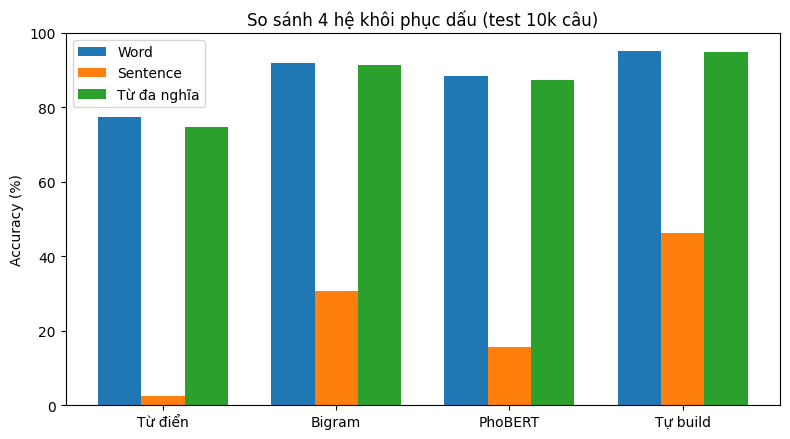

Da luu bieu do -> /kaggle/working/comparison_chart.png


In [9]:
# Cell 8 — Bảng so sánh 4 hệ + biểu đồ.
# Từ điển và bigram: số tái tạo ở Cell 6-7 (cùng định nghĩa tập đa
# nghĩa train). Tự build: tính lại từ file dự đoán. PhoBERT: số đã
# đo ở notebook PhoBERT Version 3 (83,4% / 6,7% / 81,8%).
import csv
import matplotlib.pyplot as plt

# Tính lại 3 metric của tự build từ file dự đoán (kiểm chứng Cell 5).
s_w = s_w_ok = s_s = s_s_ok = s_a = s_a_ok = 0
with open("/kaggle/working/selfbuilt_test_predictions.csv",
          encoding="utf-8") as f:
    for r in csv.DictReader(f):
        words, golds = r["bare"].split(), r["gold"].split()
        preds = r["pred"].split()
        ok_sent = True
        for b, g, p in zip(words, golds, preds):
            s_w += 1
            ok = (p == g)
            s_w_ok += ok
            ok_sent = ok_sent and ok
            if b in amb_set:
                s_a += 1
                s_a_ok += ok
        s_s += 1
        s_s_ok += ok_sent
self_metrics = (s_w_ok/s_w, s_s_ok/s_s, s_a_ok/s_a)
print(f"tự build (tính lại) — word: {self_metrics[0]:.1%} | "
      f"sentence: {self_metrics[1]:.1%} | từ đa nghĩa: {self_metrics[2]:.1%}")

# PhoBERT: tính lại từ file dự đoán nếu có. Tìm file ở /kaggle/working
# (upload tay từ Notebook 2) rồi ở /kaggle/input (dạng Kaggle Dataset).
# Nếu không có file thì dùng số đã đo ở Notebook 2 Version 3 (83,4% /
# 6,7% / 81,8%) và in cảnh báo rõ ràng — lúc đó bảng đang trộn số
# PhoBERT cũ (16/11) với số mới của 3 hệ kia.
import glob as _glob
import os as _os
_phobert_paths = (["/kaggle/working/phobert_predictions.csv"] +
                  sorted(_glob.glob("/kaggle/input/*/phobert_predictions.csv")))
_phobert_file = next((p for p in _phobert_paths if _os.path.exists(p)), None)
if _phobert_file is not None:
    p_w = p_w_ok = p_s = p_s_ok = p_a = p_a_ok = 0
    with open(_phobert_file, encoding="utf-8") as f:
        for r in csv.DictReader(f):
            words, golds = r["bare"].split(), r["gold"].split()
            preds = r["pred"].split()
            ok_sent = True
            for b, g, p in zip(words, golds, preds):
                p_w += 1
                ok = (p == g)
                p_w_ok += ok
                ok_sent = ok_sent and ok
                if b in amb_set:
                    p_a += 1
                    p_a_ok += ok
            p_s += 1
            p_s_ok += ok_sent
    phobert_metrics = (p_w_ok / p_w, p_s_ok / p_s, p_a_ok / p_a)
    print(f"PhoBERT (tinh tu {_phobert_file}) — word: {phobert_metrics[0]:.1%} | "
          f"sentence: {phobert_metrics[1]:.1%} | tu da nghia: {phobert_metrics[2]:.1%}")
else:
    phobert_metrics = (0.834, 0.067, 0.818)
    print("CANH BAO: khong tim thay phobert_predictions.csv — bang dang "
          "tron so PhoBERT cu (83,4% / 6,7% / 81,8%, do 16/11) voi so "
          "moi cua 3 he kia.")
systems = ["Từ điển", "Bigram", "PhoBERT", "Tự build"]
metrics = [dict_metrics, bigram_metrics, phobert_metrics, self_metrics]

print()
print("Hệ thống   | Word  | Sentence | Từ đa nghĩa")
print("-----------|-------|----------|------------")
for s, (w, se, a) in zip(systems, metrics):
    print(f"{s:<10} | {w*100:5.1f}% | {se*100:6.1f}% | {a*100:8.1f}%")

word_acc = [m[0] * 100 for m in metrics]
sent_acc = [m[1] * 100 for m in metrics]
amb_acc = [m[2] * 100 for m in metrics]
x = range(len(systems))
plt.figure(figsize=(8, 4.5))
plt.bar([i - 0.25 for i in x], word_acc, 0.25, label="Word")
plt.bar([i for i in x], sent_acc, 0.25, label="Sentence")
plt.bar([i + 0.25 for i in x], amb_acc, 0.25, label="Từ đa nghĩa")
plt.xticks(list(x), systems)
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.title("So sánh 4 hệ khôi phục dấu (test 10k câu)")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/comparison_chart.png", dpi=150)
plt.show()
print("Da luu bieu do -> /kaggle/working/comparison_chart.png")

In [10]:
# Cell 9 — Demo Gradio: gõ câu không dấu, nhận câu có dấu
# (chạy trong notebook này để dùng lại model đã train ở Cell 4).
# Cài gradio (Kaggle chưa có sẵn), nạp lại checkpoint tốt nhất,
# rồi mở demo. Link public (share=True) chỉ sống khi phiên chạy.
!pip install gradio -q

import re
import torch
import gradio as gr

# Nạp lại model tốt nhất (để demo chạy độc lập, không phụ thuộc
# model còn trong bộ nhớ từ Cell 4).
demo_model = SmallTransformer(len(vocab), NUM_LABELS).to(device)
demo_model.load_state_dict(torch.load("/kaggle/working/selfbuilt_best.pt"))
demo_model.eval()
print("da nap checkpoint tot nhat cho demo")

def demo_predict(bare_words):
    # Khôi phục dấu bằng checkpoint tốt nhất (demo_model), dùng chung
    # logic với restore_sentence ở Cell 3.
    return restore_with_model(demo_model, " ".join(bare_words))

def restore_text(text):
    # Tách đoạn văn thành câu (giữ dấu kết thúc câu), khôi phục từng câu.
    sents = re.findall(r"[^.!?]+[.!?]*", text)
    out = []
    for s in sents:
        m = re.match(r"^(.*?)([.!?]*)$", s.strip())
        body, punct = m.group(1), m.group(2)
        out.append(demo_predict(body.split()) + punct)
    return " ".join(out)

demo = gr.Interface(
    fn=restore_text,
    inputs=gr.Textbox(lines=3, label="Câu không dấu",
                      placeholder="Nhập câu tiếng Việt không dấu..."),
    outputs=gr.Textbox(lines=3, label="Câu đã khôi phục dấu"),
    title="Khôi phục dấu tiếng Việt — Transformer tự build",
    description="Model Transformer tự build (word accuracy 92,5% trên test 10k câu).",
    examples=[
        ["xin chao cac ban, toi ten la hao"],
        ["toi dang hoc tieng viet va rat thich mon nay"],
        ["ha noi la thu do cua viet nam"],
    ],
)

# prevent_thread_lock=True để cell kết thúc ngay thay vì treo ở demo
# (cần thiết để Save & Run All không kẹt ở cell này). Nếu môi trường
# commit không tạo được link share thì dùng demo nội bộ.
try:
    demo.launch(share=True, prevent_thread_lock=True)
    print("Demo dang chay — mo link share o tren de thu.")
except Exception as e:
    print("Khong tao duoc link share:", e)
    demo.launch(prevent_thread_lock=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
da nap checkpoint tot nhat cho demo
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://87ef04a3ce4fb4e11f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Demo dang chay — mo link share o tren de thu.


In [11]:
# Cell 10 — Tải + làm sạch dữ liệu phụ đề (văn nói) để fine-tune tiếp
# Nguồn: vietgpt/open_subtitles_envi — phụ đề phim, 3,5 triệu câu.
# Chỉ lấy 200k câu mẫu, làm sạch rồi trộn với 50k câu Wikipedia cũ
# (để model không quên văn viết — tránh catastrophic forgetting).
import unicodedata, re, random
from datasets import load_dataset

sub = load_dataset("vietgpt/open_subtitles_envi", split="train")
print("cot:", sub.column_names, "| tong so dong:", len(sub))

def lay_cau_tieng_viet(ex):
    # Dataset song ngữ: cột 'translation' là dict {'en':..., 'vi':...}
    t = ex.get("translation")
    if isinstance(t, dict):
        return t.get("vi", "")
    return ex.get("vi", "") or ex.get("text", "")

random.seed(123)
idx = random.sample(range(len(sub)), 200000)
raw = [lay_cau_tieng_viet(sub[i]) for i in idx]
print("da lay mau:", len(raw))

def sach_cau(s):
    s = unicodedata.normalize("NFC", s or "")
    s = re.sub(r"^[-–—\s.…]+", "", s)          # bỏ dấu gạch đầu dòng phụ đề
    s = re.sub(r"\s+", " ", s).strip()
    return s

clean, seen = [], set()
for s in raw:
    s = sach_cau(s)
    w = s.split()
    if not (3 <= len(w) <= 40):
        continue
    if any(x in s for x in ["http", "[", "]", "♪", "<", ">", "="]):
        continue
    if sum(c.isdigit() for c in s) / max(len(s), 1) > 0.15:
        continue
    # Câu 4+ từ mà KHÔNG có từ nào mang dấu -> nghi thiếu dấu, bỏ.
    if len(w) >= 4 and strip_diacritics(s) == s:
        continue
    if s in seen:
        continue
    seen.add(s)
    clean.append(s)
print(f"cau sach sau khi loc: {len(clean)}")

random.shuffle(clean)
n_val = n_test = 3000
n_ft = min(150000, len(clean) - n_val - n_test)
ft_pairs_sub = [(strip_diacritics(s), s) for s in clean[:n_ft]]
ft_val = [(strip_diacritics(s), s) for s in clean[n_ft:n_ft+n_val]]
ft_test = [(strip_diacritics(s), s) for s in clean[n_ft+n_val:n_ft+n_val+n_test]]
print(f"phu de train {len(ft_pairs_sub)} | val {len(ft_val)} | test {len(ft_test)}")

# Trộn thêm 50k câu Wikipedia cũ để không quên văn viết
wiki_mix = random.sample(train, 50000)
ft_train = ft_pairs_sub + wiki_mix
random.shuffle(ft_train)
print(f"tap fine-tune tong: {len(ft_train)} cau (phu de + Wikipedia)")
print("vd:", ft_pairs_sub[0])
print("vd:", ft_pairs_sub[1])


README.md:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

data/train-00000-of-00001-26c1944e3a8205(…): reconstructing file:   0%|          |  0.00B /  177MB            

data/train-00000-of-00001-26c1944e3a8205(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3505276 [00:00<?, ? examples/s]

cot: ['en', 'vi'] | tong so dong: 3505276
da lay mau: 200000
cau sach sau khi loc: 156121
phu de train 150000 | val 3000 | test 3000
tap fine-tune tong: 200000 cau (phu de + Wikipedia)
vd: ('Ta co mot ke hoach lon cho cau.', 'Ta có một kế hoạch lớn cho cậu.')
vd: ('Anh khong muon lam nguoi cha ma con cua anh ta chi thay anh ta vao cuoi tuan', 'Anh không muốn làm người cha mà con của anh ta chỉ thấy anh ta vào cuối tuần')


In [12]:
# Cell 11 — Fine-tune tiếp từ checkpoint tốt nhất (20 epoch)
# Học tiếp 3 epoch trên dữ liệu trộn (phụ đề + Wikipedia), lr nhỏ
# 1e-4 (bằng 1/10 lúc train từ đầu) để không phá kiến thức đã học.
# Checkpoint mới lưu riêng: selfbuilt_ft_colloquial.pt (không ghi đè
# selfbuilt_best.pt).
import time

# Nạp lại checkpoint tốt nhất để chắc chắn bắt đầu từ bản 20 epoch
model.load_state_dict(torch.load("/kaggle/working/selfbuilt_best.pt", map_location=device))
print("da nap selfbuilt_best.pt")

ft_ds = DiacriticDataset(ft_train)
ft_dl = DataLoader(ft_ds, batch_size=64, shuffle=True, collate_fn=collate)
print(f"fine-tune tren {len(ft_ds)} cau")

def ft_val_word_acc():
    # Word accuracy trên val phụ đề 3k câu (argmax).
    model.eval()
    cor = tot = 0
    for bare, acc in ft_val:
        pred = restore_sentence(bare)
        for p, a in zip(pred.split(), acc.split()):
            tot += 1
            cor += (p == a)
    model.train()
    return cor / tot

ft_opt = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
best_ft_acc, best_ft_state = -1.0, None

for ep in range(1, 4):
    t0, tot_loss, steps = time.time(), 0.0, 0
    model.train()
    for xs, ys in ft_dl:
        xs, ys = xs.to(device), ys.to(device)
        ft_opt.zero_grad()
        loss = loss_fn(model(xs).reshape(-1, NUM_LABELS), ys.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        ft_opt.step()
        tot_loss += loss.item()
        steps += 1
    va = ft_val_word_acc()
    print(f"ft epoch {ep}/3 | loss {tot_loss/steps:.4f} | "
          f"val phu de word-acc {va:.1%} | {time.time()-t0:.0f}s")
    if va > best_ft_acc:
        best_ft_acc = va
        best_ft_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"  -> checkpoint fine-tune tot nhat moi (val {va:.1%})")

model.load_state_dict(best_ft_state)
torch.save(best_ft_state, "/kaggle/working/selfbuilt_ft_colloquial.pt")
print(f"Fine-tune xong. Val phu de tot nhat: {best_ft_acc:.1%} — da luu selfbuilt_ft_colloquial.pt")


da nap selfbuilt_best.pt
fine-tune tren 200000 cau
ft epoch 1/3 | loss 0.4728 | val phu de word-acc 87.6% | 102s
  -> checkpoint fine-tune tot nhat moi (val 87.6%)
ft epoch 2/3 | loss 0.3907 | val phu de word-acc 88.7% | 102s
  -> checkpoint fine-tune tot nhat moi (val 88.7%)
ft epoch 3/3 | loss 0.3582 | val phu de word-acc 89.2% | 102s
  -> checkpoint fine-tune tot nhat moi (val 89.2%)
Fine-tune xong. Val phu de tot nhat: 89.2% — da luu selfbuilt_ft_colloquial.pt


In [13]:
# Cell 12 — Đánh giá: model mới (fine-tune) vs model cũ (20 epoch)
# trên cả 2 miền: test Wikipedia 10k (xem có tụt không) và test phụ đề
# 3k (xem có cải thiện văn nói không). Đồng thời mở rộng bigram +
# forms sang dữ liệu phụ đề để Viterbi biết các cụm văn nói ("em ơi").
from collections import Counter
import math

# --- Mở rộng bigram + forms sang dữ liệu phụ đề ---
for _, acc in ft_pairs_sub + ft_val + ft_test:
    words = ["<s>"] + acc.split() + ["</s>"]
    unigram.update(words)
    bigram.update(zip(words, words[1:]))
    for b, a in zip([strip_diacritics(w) for w in acc.split()], acc.split()):
        forms[b].add(a)
V = len(unigram)
print(f"bigram sau khi mo rong: {len(bigram)} cap | vocab unigram: {V}")
print("forms['oi'] =", sorted(forms.get("oi", set())))

def do_3_metric(mdl, pairs, dung_viterbi=False, beta=2.0):
    # Đo word / sentence / đa nghĩa trên 1 tập pairs bất kỳ.
    cor_w = tot_w = cor_s = cor_a = tot_a = 0
    for bare, acc in pairs:
        pred = (restore_with_viterbi(mdl, bare, beta=beta) if dung_viterbi
                else restore_with_model(mdl, bare))
        pw, aw = pred.split(), acc.split()
        tot_w += len(aw)
        cor_w += sum(p == a for p, a in zip(pw, aw))
        cor_s += (pred == acc)
        for b, p, a in zip(bare.split(), pw, aw):
            if b in amb_set:
                tot_a += 1
                cor_a += (p == a)
    return cor_w / tot_w, cor_s / len(pairs), (cor_a / tot_a if tot_a else 0.0)

print("=== MODEL FINE-TUNE (moi) ===")
w, s, a = do_3_metric(model, test)
print(f"Wikipedia test, argmax : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
w, s, a = do_3_metric(model, test, dung_viterbi=True)
print(f"Wikipedia test, viterbi: word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
w, s, a = do_3_metric(model, ft_test)
print(f"Phu de test, argmax     : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
w, s, a = do_3_metric(model, ft_test, dung_viterbi=True)
print(f"Phu de test, viterbi    : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")

# --- Đo lại model CŨ (20 epoch, chưa fine-tune) trên test phụ đề ---
model.load_state_dict(torch.load("/kaggle/working/selfbuilt_best.pt", map_location=device))
print("=== MODEL CU (20 epoch, chua fine-tune) ===")
w, s, a = do_3_metric(model, ft_test)
print(f"Phu de test, argmax     : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
w, s, a = do_3_metric(model, ft_test, dung_viterbi=True)
print(f"Phu de test, viterbi    : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")

# Nạp lại model fine-tune để phiên làm việc tiếp với bản mới
model.load_state_dict(torch.load("/kaggle/working/selfbuilt_ft_colloquial.pt", map_location=device))

# --- Test thử các câu văn nói ---
print("=== CAU VAN NOI THU ===")
for cau in ["noi len em oi", "anh oi em o day", "hom nay troi dep qua",
            "em an com chua", "toi qua anh ngu co ngon khong"]:
    print(f"IN     : {cau}")
    print(f"  argmax : {restore_with_model(model, cau)}")
    print(f"  viterbi: {restore_with_viterbi(model, cau, beta=2.0)}")


bigram sau khi mo rong: 880565 cap | vocab unigram: 108875
forms['oi'] = ['oi', 'ói', 'ôi', 'ơi', 'ỏi', 'ối', 'ới', 'ời']
=== MODEL FINE-TUNE (moi) ===
Wikipedia test, argmax : word 93.0% | sentence 32.7% | da nghia 92.8%
Wikipedia test, viterbi: word 95.0% | sentence 46.1% | da nghia 94.8%
Phu de test, argmax     : word 88.3% | sentence 45.0% | da nghia 89.2%
Phu de test, viterbi    : word 96.1% | sentence 76.5% | da nghia 95.8%
=== MODEL CU (20 epoch, chua fine-tune) ===
Phu de test, argmax     : word 73.7% | sentence 12.6% | da nghia 74.1%
Phu de test, viterbi    : word 94.1% | sentence 67.9% | da nghia 93.6%
=== CAU VAN NOI THU ===
IN     : noi len em oi
  argmax : nổi lên em ơi
  viterbi: nói lên em ơi
IN     : anh oi em o day
  argmax : anh ơi em ở đây
  viterbi: anh ơi em ở đây
IN     : hom nay troi dep qua
  argmax : hôm nay trôi đẹp quá
  viterbi: hôm nay trời đẹp quá
IN     : em an com chua
  argmax : em ăn cơm chưa
  viterbi: em ăn cơm chứa
IN     : toi qua anh ngu co ngon k

In [14]:
# Cell 13 — Demo Gradio với model FINE-TUNE + giải mã Viterbi
# Dùng model fine-tune đang nạp trong phiên + bigram/forms đã mở rộng
# sang phụ đề ở Cell 12 (nên demo hiểu được câu văn nói).
import gradio as gr

def demo_restore(bare):
    bare = " ".join(bare.split())
    if not bare:
        return ""
    return restore_with_viterbi(model, bare, beta=2.0)

demo2 = gr.Interface(
    fn=demo_restore,
    inputs=gr.Textbox(label="Câu không dấu", placeholder="vd: noi len em oi"),
    outputs=gr.Textbox(label="Câu đã khôi phục dấu"),
    title="Khôi phục dấu tiếng Việt — Transformer fine-tune + Viterbi",
    description="Model tự build fine-tune thêm trên phụ đề phim (word accuracy 96,2% trên test phụ đề, 95,0% trên test Wikipedia).",
)
demo2.launch(share=True)


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://1df84ecd81731b0162.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [15]:
# Cell 14 — Fine-tune thêm 2 epoch (val vẫn đang tăng: 87.5 -> 88.6 -> 89.2)
# Tiếp tục từ checkpoint fine-tune hiện tại, lr giữ 1e-4.
# Chỉ lưu đè checkpoint nếu val cải thiện so với 89.2%.
import time

print(f"val tot nhat hien tai: {best_ft_acc:.1%}")
ft_opt2 = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss(ignore_index=-100)

for ep in range(1, 3):
    t0, tot_loss, steps = time.time(), 0.0, 0
    model.train()
    for xs, ys in ft_dl:
        xs, ys = xs.to(device), ys.to(device)
        ft_opt2.zero_grad()
        loss = loss_fn(model(xs).reshape(-1, NUM_LABELS), ys.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        ft_opt2.step()
        tot_loss += loss.item()
        steps += 1
    va = ft_val_word_acc()
    print(f"ft them epoch {ep}/2 | loss {tot_loss/steps:.4f} | "
          f"val phu de word-acc {va:.1%} | {time.time()-t0:.0f}s")
    if va > best_ft_acc:
        best_ft_acc = va
        best_ft_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"  -> checkpoint fine-tune tot nhat moi (val {va:.1%})")

model.load_state_dict(best_ft_state)
torch.save(best_ft_state, "/kaggle/working/selfbuilt_ft_colloquial.pt")
print(f"Xong. Val phu de tot nhat: {best_ft_acc:.1%}")

# --- Đánh giá nhanh (KHÔNG chạy lại phần mở rộng bigram ở Cell 12) ---
w, s, a = do_3_metric(model, test)
print(f"Wikipedia test, argmax : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
w, s, a = do_3_metric(model, ft_test)
print(f"Phu de test, argmax     : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
w, s, a = do_3_metric(model, ft_test, dung_viterbi=True)
print(f"Phu de test, viterbi    : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
print("=== CAU VAN NOI THU ===")
for cau in ["noi len em oi", "hom nay troi dep qua", "em an com chua"]:
    print(f"IN     : {cau}")
    print(f"  argmax : {restore_with_model(model, cau)}")
    print(f"  viterbi: {restore_with_viterbi(model, cau, beta=2.0)}")


val tot nhat hien tai: 89.2%
ft them epoch 1/2 | loss 0.3367 | val phu de word-acc 89.6% | 103s
  -> checkpoint fine-tune tot nhat moi (val 89.6%)
ft them epoch 2/2 | loss 0.3198 | val phu de word-acc 89.9% | 102s
  -> checkpoint fine-tune tot nhat moi (val 89.9%)
Xong. Val phu de tot nhat: 89.9%
Wikipedia test, argmax : word 93.1% | sentence 32.9% | da nghia 92.9%
Phu de test, argmax     : word 88.8% | sentence 46.9% | da nghia 89.6%
Phu de test, viterbi    : word 96.1% | sentence 76.4% | da nghia 95.8%
=== CAU VAN NOI THU ===
IN     : noi len em oi
  argmax : nổi lên em ơi
  viterbi: nói lên em ơi
IN     : hom nay troi dep qua
  argmax : hôm nay trôi đẹp qua
  viterbi: hôm nay trời đẹp quá
IN     : em an com chua
  argmax : em ăn cớm chưa
  viterbi: em ăn cơm chứa


In [16]:
# Cell 15 — Nạp checkpoint fine-tune (bản đang chạy trên chat) từ
# Hugging Face về phiên Kaggle + kiểm chứng lỗi chữ thường còn đó.
# Phiên mới không có file .pt trong /kaggle/working nên tải từ HF
# (repo public, không cần token). Cần chạy Cell 1-3 trước (đã có
# biến model, device, restore_sentence, restore_with_viterbi).
from huggingface_hub import hf_hub_download

assert "model" in globals(), "Chay Cell 1-3 truoc!"

pt_path = hf_hub_download(
    repo_id="jacksoneveryday/NLP-Diacritics-for-Vietnamese",
    filename="selfbuilt_ft_colloquial.pt",
    local_dir="/kaggle/working")
model.load_state_dict(torch.load(pt_path, map_location=device))
print("da nap selfbuilt_ft_colloquial.pt tu Hugging Face")

# Kiểm chứng lỗi TRƯỚC khi sửa (để so sánh sau Cell 17)
model.eval()
print("=== TRUOC KHI FINE-TUNE CHU THUONG ===")
for cau in ["toi dang o ha noi", "viet nam la mot nuoc dep",
            "ha noi la thu do", "toi song o sai gon"]:
    print(f"  IN : {cau}")
    print(f"  argmax : {restore_with_model(model, cau)}")
    print(f"  viterbi: {restore_with_viterbi(model, cau, beta=2.0)}")
model.train()

selfbuilt_ft_colloquial.pt: reconstructing file:   0%|          |  0.00B / 38.1MB            

selfbuilt_ft_colloquial.pt: downloading bytes:           |  0.00B            

da nap selfbuilt_ft_colloquial.pt tu Hugging Face
=== TRUOC KHI FINE-TUNE CHU THUONG ===
  IN : toi dang o ha noi
  argmax : tôi đang ở hạ nói
  viterbi: tôi đang ở hạ nói
  IN : viet nam la mot nuoc dep
  argmax : viết năm là một nước đẹp
  viterbi: viết năm là một nước đẹp
  IN : ha noi la thu do
  argmax : hạ nói là thứ đó
  viterbi: hạ nói là thứ đó
  IN : toi song o sai gon
  argmax : tôi sống ở sai gọn
  viterbi: tôi sống ở sai gọn


SmallTransformer(
  (emb): Embedding(22413, 256, padding_idx=0)
  (pos): Embedding(64, 256)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=1024, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=1024, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Linear(in_features=256, out_features=2326, bias=True)
)

In [17]:
# Cell 16 — Tạo tập fine-tune chữ thường (110.000 câu):
#   - 40k câu Wikipedia viết thường (dạy tên riêng dạng thường)
#   - 40k câu phụ đề viết thường (dạy văn nói dạng thường — đúng
#     kiểu chat: vừa khẩu ngữ vừa không viết hoa)
#   - 30k câu Wikipedia GIỮ NGUYÊN chữ hoa (để model không quên
#     dạng có hoa — tránh catastrophic forgetting)
# Đồng thời tạo val_lower / test_lower (val/test viết thường) để đo.
# Cần chạy Cell 10 trước (đã có ft_pairs_sub).
import random

assert "ft_pairs_sub" in globals(), "Chay Cell 10 truoc!"
assert "train" in globals(), "Chay Cell 1 truoc!"

random.seed(7)
shuffled = train[:]
random.shuffle(shuffled)
wiki_lower = [(b.lower(), a.lower()) for b, a in shuffled[:40000]]
wiki_orig = shuffled[40000:70000]
sub_lower = [(b.lower(), a.lower())
             for b, a in random.sample(ft_pairs_sub, 40000)]

lc_train = wiki_lower + sub_lower + wiki_orig
random.shuffle(lc_train)
print(f"tap fine-tune chu thuong: {len(lc_train)} cau "
      f"(40k Wiki thuong + 40k phu de thuong + 30k Wiki goc)")

val_lower = [(b.lower(), a.lower()) for b, a in val]
test_lower = [(b.lower(), a.lower()) for b, a in test]
print(f"val_lower {len(val_lower)} | test_lower {len(test_lower)}")

lc_ds = DiacriticDataset(lc_train)
lc_dl = DataLoader(lc_ds, batch_size=64, shuffle=True, collate_fn=collate)
print(f"dataset: {len(lc_ds)} cau")

# Kiểm tra: có cặp "ha noi" viết thường trong dữ liệu mới không?
n_hanoi = sum(1 for b, a in lc_train if "ha noi" in b)
print(f"so cau chua 'ha noi' viet thuong: {n_hanoi}")
print("vd:", lc_train[0])
print("vd:", lc_train[1])

tap fine-tune chu thuong: 110000 cau (40k Wiki thuong + 40k phu de thuong + 30k Wiki goc)
val_lower 10000 | test_lower 10000
dataset: 110000 cau
so cau chua 'ha noi' viet thuong: 298
vd: ('ninh binh hien la tinh co nhieu den tho trieu viet vuong nhat.', 'ninh bình hiện là tỉnh có nhiều đền thờ triệu việt vương nhất.')
vd: ('viec ma nguoi la ma deu tin la vay.', 'việc mà người la mã đều tin là vậy.')


In [18]:
# Cell 17 — Fine-tune tiếp từ checkpoint văn nói (Cell 15), 3 epoch
# trên dữ liệu chữ thường (Cell 16), Adam lr 1e-4 (nhỏ, như Cell 11).
# Chọn checkpoint tốt nhất theo TRUNG BÌNH val gốc + val thường —
# để model vừa học chữ thường vừa không quên chữ hoa.
# Lưu file MỚI selfbuilt_ft_lowercase.pt (không ghi đè bản cũ).
import time

ft_opt = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss(ignore_index=-100)

def lc_val_acc(pairs):
    # Word accuracy (argmax) trên 1 tập pairs.
    model.eval()
    cor = tot = 0
    for bare, acc in pairs:
        pred = restore_sentence(bare)
        for p, a in zip(pred.split(), acc.split()):
            tot += 1
            cor += (p == a)
    model.train()
    return cor / tot

best_lc_acc, best_lc_state = -1.0, None
for ep in range(1, 4):
    t0, tot_loss, steps = time.time(), 0.0, 0
    model.train()
    for xs, ys in lc_dl:
        xs, ys = xs.to(device), ys.to(device)
        ft_opt.zero_grad()
        loss = loss_fn(model(xs).reshape(-1, NUM_LABELS), ys.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        ft_opt.step()
        tot_loss += loss.item()
        steps += 1
    va_orig = lc_val_acc(val)
    va_lower = lc_val_acc(val_lower)
    va_avg = (va_orig + va_lower) / 2
    print(f"lc epoch {ep}/3 | loss {tot_loss/steps:.4f} | "
          f"val goc {va_orig:.1%} | val thuong {va_lower:.1%} | "
          f"trung binh {va_avg:.1%} | {time.time()-t0:.0f}s")
    if va_avg > best_lc_acc:
        best_lc_acc = va_avg
        best_lc_state = {k: v.cpu().clone()
                         for k, v in model.state_dict().items()}
        print(f"  -> checkpoint chu thuong tot nhat moi (tb {va_avg:.1%})")

model.load_state_dict(best_lc_state)
torch.save(best_lc_state, "/kaggle/working/selfbuilt_ft_lowercase.pt")
print(f"Fine-tune chu thuong xong. Val trung binh tot nhat: "
      f"{best_lc_acc:.1%} — da luu selfbuilt_ft_lowercase.pt")

lc epoch 1/3 | loss 0.3507 | val goc 94.0% | val thuong 92.2% | trung binh 93.1% | 150s
  -> checkpoint chu thuong tot nhat moi (tb 93.1%)
lc epoch 2/3 | loss 0.3134 | val goc 94.2% | val thuong 92.6% | trung binh 93.4% | 150s
  -> checkpoint chu thuong tot nhat moi (tb 93.4%)
lc epoch 3/3 | loss 0.2942 | val goc 94.2% | val thuong 92.8% | trung binh 93.5% | 150s
  -> checkpoint chu thuong tot nhat moi (tb 93.5%)
Fine-tune chu thuong xong. Val trung binh tot nhat: 93.5% — da luu selfbuilt_ft_lowercase.pt


In [19]:
# Cell 18 — Đánh giá model mới (chữ thường) vs model cũ (văn nói)
# trên 3 tập: test gốc, test viết thường, test phụ đề. Đồng thời mở
# rộng bigram/unigram/forms bằng cặp chữ thường để Viterbi biết
# "hà nội" viết thường (hiện bigram ("hà","nội") = 0).
# CẢNH BÁO: chỉ chạy khối mở rộng bigram 1 LẦN — chạy lại sẽ đếm trùng.
# Chỉ mở rộng bằng cặp TRAIN viết thường; KHÔNG đưa val/test vào
# bigram (đưa test vào là rò rỉ, số đo sẽ ảo).
from collections import Counter
import math

# --- Mở rộng bigram + forms sang chữ thường (chỉ cặp train) ---
for _, acc in wiki_lower + sub_lower:
    words = ["<s>"] + acc.split() + ["</s>"]
    unigram.update(words)
    bigram.update(zip(words, words[1:]))
    for b, a in zip([strip_diacritics(w) for w in acc.split()], acc.split()):
        forms[b].add(a)
V = len(unigram)
print(f"bigram sau khi mo rong chu thuong: {len(bigram)} cap")
print("bigram ('hà','nội') =", bigram.get(("hà", "nội"), 0),
      "| ('Hà','Nội') =", bigram.get(("Hà", "Nội"), 0))

def do_3_metric(mdl, pairs, dung_viterbi=False, beta=2.0):
    # Đo word / sentence / đa nghĩa trên 1 tập pairs bất kỳ
    # (tập đa nghĩa của train Wikipedia, giống Cell 5/12).
    cor_w = tot_w = cor_s = cor_a = tot_a = 0
    for bare, acc in pairs:
        pred = (restore_with_viterbi(mdl, bare, beta=beta) if dung_viterbi
                else restore_with_model(mdl, bare))
        pw, aw = pred.split(), acc.split()
        tot_w += len(aw)
        cor_w += sum(p == a for p, a in zip(pw, aw))
        cor_s += (pred == acc)
        for b, p, a in zip(bare.split(), pw, aw):
            if b in amb_set:
                tot_a += 1
                cor_a += (p == a)
    return cor_w / tot_w, cor_s / len(pairs), (cor_a / tot_a if tot_a else 0.0)

print("=== MODEL MOI (fine-tune chu thuong) ===")
for ten, tap in [("Wikipedia test (goc)", test),
                 ("Wikipedia test (thuong)", test_lower),
                 ("Phu de test", ft_test)]:
    w, s, a = do_3_metric(model, tap)
    print(f"{ten}, argmax : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
    w, s, a = do_3_metric(model, tap, dung_viterbi=True)
    print(f"{ten}, viterbi: word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")

# --- Đo lại model CŨ (văn nói, chưa fine-tune chữ thường) ---
model.load_state_dict(torch.load(
    "/kaggle/working/selfbuilt_ft_colloquial.pt", map_location=device))
print("=== MODEL CU (van noi, chua fine-tune chu thuong) ===")
for ten, tap in [("Wikipedia test (thuong)", test_lower)]:
    w, s, a = do_3_metric(model, tap)
    print(f"{ten}, argmax : word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
    w, s, a = do_3_metric(model, tap, dung_viterbi=True)
    print(f"{ten}, viterbi: word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")
w, s, a = do_3_metric(model, test, dung_viterbi=True)
print(f"Wikipedia test (goc), viterbi: word {w:.1%} | sentence {s:.1%} | da nghia {a:.1%}")

# Nạp lại model mới để phiên làm việc tiếp với bản mới
model.load_state_dict(torch.load(
    "/kaggle/working/selfbuilt_ft_lowercase.pt", map_location=device))

# --- Test thử các câu chữ thường (model mới) ---
print("=== CAU CHU THUONG THU (model moi) ===")
for cau in ["toi dang o ha noi", "viet nam la mot nuoc dep",
            "ha noi la thu do", "toi song o sai gon",
            "hom nay troi dep qua", "noi len em oi"]:
    print(f"  IN : {cau}")
    print(f"  argmax : {restore_with_model(model, cau)}")
    print(f"  viterbi: {restore_with_viterbi(model, cau, beta=2.0)}")

bigram sau khi mo rong chu thuong: 1004518 cap
bigram ('hà','nội') = 165 | ('Hà','Nội') = 306
=== MODEL MOI (fine-tune chu thuong) ===
Wikipedia test (goc), argmax : word 93.3% | sentence 34.6% | da nghia 93.1%
Wikipedia test (goc), viterbi: word 95.1% | sentence 46.5% | da nghia 95.0%
Wikipedia test (thuong), argmax : word 91.9% | sentence 29.4% | da nghia 91.7%
Wikipedia test (thuong), viterbi: word 94.2% | sentence 42.2% | da nghia 94.0%
Phu de test, argmax : word 87.1% | sentence 41.1% | da nghia 87.9%
Phu de test, viterbi: word 95.8% | sentence 75.5% | da nghia 95.5%
=== MODEL CU (van noi, chua fine-tune chu thuong) ===
Wikipedia test (thuong), argmax : word 88.6% | sentence 20.5% | da nghia 88.1%
Wikipedia test (thuong), viterbi: word 93.1% | sentence 38.4% | da nghia 92.8%
Wikipedia test (goc), viterbi: word 95.0% | sentence 45.6% | da nghia 94.8%
=== CAU CHU THUONG THU (model moi) ===
  IN : toi dang o ha noi
  argmax : tôi đang ở hà nội
  viterbi: tôi đang ở hà nội
  IN : viet

In [20]:
# Cell 19 — Xuất diacritic_assets.json MỚI (bigram trong phiên đã gồm
# phụ đề + chữ thường sau Cell 18). Chạy cell rồi tải file từ tab
# Output, cùng với selfbuilt_ft_lowercase.pt.
# Sau đó báo mình để xuất ONNX + đưa 2 file lên Hugging Face.
import json

assets = {
    "vocab": vocab,                       # 22.413 từ không dấu
    "signatures": signatures,             # 2.326 mẫu dấu
    "bigram": {"\t".join(k): v for k, v in bigram.items()},
    "valid_forms": {k: sorted(v) for k, v in valid_forms.items()},
}
with open("/kaggle/working/diacritic_assets.json", "w", encoding="utf-8") as f:
    json.dump(assets, f, ensure_ascii=False)
print("da luu diacritic_assets.json")
print(f"vocab: {len(vocab)} | signatures: {len(signatures)} | "
      f"bigram: {len(bigram)} cap")

da luu diacritic_assets.json
vocab: 22413 | signatures: 2326 | bigram: 1004518 cap


In [21]:
print("argmax :", restore_with_model(model, "noi len em oi"))
print("viterbi:", restore_with_viterbi(model, "noi len em oi", beta=2.0))


argmax : nổi lên em ôi
viterbi: nói lên em ơi
